In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets,transforms
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import numpy as np

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

print(os.listdir('/content'))

['.config', 'drive', 'sample_data']


In [4]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'nid-5115523341.pdf', 'nid-5115523341 (1).pdf', 'Classroom', 'kahium fahim.pdf', 'Google AI Studio', 'Music', 'Assistant Software Engineer Recruitment Project - 8b05df34-4545-4fb1-b7a1-f9ab87a32c50_14346740-86b3-41e9-b4d6-9f00380b0290_copy.pdf', 'COA Final-Term Notes (Complete)_copy.pdf', "I am sharing 'COA Practive Sheet Chapter 6 and 7 Output' with you.pdf", "I am sharing 'Rise_CRM_SRS' with you.pdf", 'Kahium_Ahamed_Fahim_Resume (6).pdf', 'Kahium_Ahamed_Fahim_Resume (5).pdf', 'Kahium_Ahamed_Fahim_Resume (4).pdf', 'inbound1932033624517605882.pdf', 'Kahium_Ahamed_Fahim_Resume (3).pdf', 'Kahium_Ahamed_Fahim_Resume (2).pdf', 'Kahium_Ahamed_Fahim_Resume (1).pdf', 'Kahium_Ahamed_Fahim_Resume.pdf', 'kahiumAhamedFahimaspdotnet-1.pdf', 'Kahium_Ahamed_Fahim_NestJS_NextJS_CV.pdf', 'Kahium_Ahamed_Fahim_ASP (2).NET_Core_CV.pdf', 'Kahium_Ahamed_Fahim_ASP (1).NET_Core_CV.pdf', 'Kahium_Ahamed_Fahim_ASP.NET_Core_CV.pdf', ' Papaya_Leaf_CNN']


In [5]:
import os

dataset_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN'

print(os.listdir(dataset_path))

['Dataset', 'Notebook']


In [6]:
dataset_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset'

print(os.listdir(dataset_path))

['Papaya Leaf Disease Dataset']


In [7]:
dataset_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset/Papaya Leaf Disease Dataset'

print(os.listdir(dataset_path))

['Papaya Leaf Disease Dataset']


In [8]:
dataset_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset/Papaya Leaf Disease Dataset'

print(os.listdir(dataset_path))

['Papaya Leaf Disease Dataset']


In [9]:
dataset_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset/Papaya Leaf Disease Dataset/Papaya Leaf Disease Dataset'

print(os.listdir(dataset_path))

['Manifest Fields Summary Table.csv', 'README.pdf', 'Augmented Dataset', 'Original Dataset']


In [10]:
original_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset/Papaya Leaf Disease Dataset/Papaya Leaf Disease Dataset/Original Dataset'

print(os.listdir(original_path))

['Original Dataset']


In [11]:
original_path = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset/Papaya Leaf Disease Dataset/Papaya Leaf Disease Dataset/Original Dataset/Original Dataset'

print(os.listdir(original_path))

['Crushed Papaya Leaves', 'Potash Deficiency', 'Mosaic', 'Healthy Leaf', 'Mold']


In [12]:
from collections import Counter
import os

for class_name in os.listdir(original_path):
    class_path = os.path.join(original_path, class_name)

    if os.path.isdir(class_path):
        images = os.listdir(class_path)
        print(f"{class_name}: {len(images)} images")

Crushed Papaya Leaves: 500 images
Potash Deficiency: 500 images
Mosaic: 500 images
Healthy Leaf: 500 images
Mold: 500 images


In [13]:
from PIL import Image

class_name = os.listdir(original_path)[0]
class_path = os.path.join(original_path, class_name)

image_name = os.listdir(class_path)[0]
image_path = os.path.join(class_path, image_name)

img = Image.open(image_path)

print("Class:", class_name)
print("Image:", image_name)
print("Size:", img.size)
print("Mode:", img.mode)

Class: Crushed Papaya Leaves
Image: image_0001.png
Size: (224, 224)
Mode: RGB


In [14]:
import os

split_base = '/content/drive/MyDrive/ Papaya_Leaf_CNN/Dataset/Papaya Leaf Disease Dataset/Papaya Leaf Disease Dataset/Split Dataset'

for split in ['train', 'val', 'test']:
    for class_name in os.listdir(original_path):
        os.makedirs(
            os.path.join(split_base, split, class_name),
            exist_ok=True
        )

print("Train, Validation and Test folders created.")

Train, Validation and Test folders created.


In [15]:
import random
import shutil

class_name = 'Crushed Papaya Leaves'

source_class_path = os.path.join(original_path, class_name)

images = [
    img for img in os.listdir(source_class_path)
    if img.lower().endswith(('.png', '.jpg', '.jpeg'))
]

random.seed(42)
random.shuffle(images)

train_images = images[:350]
val_images = images[350:400]
test_images = images[400:500]

print("Total:", len(images))
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Total: 500
Train: 350
Validation: 50
Test: 100


In [16]:
import random
import shutil
import os

random.seed(42)

classes = os.listdir(original_path)

for class_name in classes:

    source_class_path = os.path.join(original_path, class_name)

    images = [
        img for img in os.listdir(source_class_path)
        if img.lower().endswith(('.png', '.jpg', '.jpeg'))
    ]

    random.shuffle(images)

    train_images = images[:350]
    val_images = images[350:400]
    test_images = images[400:500]

    # Copy train images
    for img in train_images:
        shutil.copy2(
            os.path.join(source_class_path, img),
            os.path.join(split_base, 'train', class_name, img)
        )

    # Copy validation images
    for img in val_images:
        shutil.copy2(
            os.path.join(source_class_path, img),
            os.path.join(split_base, 'val', class_name, img)
        )

    # Copy test images
    for img in test_images:
        shutil.copy2(
            os.path.join(source_class_path, img),
            os.path.join(split_base, 'test', class_name, img)
        )

print("Dataset splitting completed.")

Dataset splitting completed.


In [17]:
for split in ['train', 'val', 'test']:

    print(f"\n--- {split.upper()} ---")

    total = 0

    for class_name in classes:
        class_path = os.path.join(split_base, split, class_name)

        count = len([
            img for img in os.listdir(class_path)
            if img.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])

        total += count

        print(f"{class_name}: {count}")

    print("Total:", total)


--- TRAIN ---
Crushed Papaya Leaves: 350
Potash Deficiency: 350
Mosaic: 350
Healthy Leaf: 350
Mold: 350
Total: 1750

--- VAL ---
Crushed Papaya Leaves: 50
Potash Deficiency: 50
Mosaic: 50
Healthy Leaf: 50
Mold: 50
Total: 250

--- TEST ---
Crushed Papaya Leaves: 100
Potash Deficiency: 100
Mosaic: 100
Healthy Leaf: 100
Mold: 100
Total: 500


In [18]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

In [19]:
from torchvision import datasets, transforms

train_path = os.path.join(split_base, 'train')

temp_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

temp_train_dataset = datasets.ImageFolder(
    root=train_path,
    transform=temp_transform
)

print("Number of training images:", len(temp_train_dataset))
print("Classes:", temp_train_dataset.classes)

Number of training images: 1750
Classes: ['Crushed Papaya Leaves', 'Healthy Leaf', 'Mold', 'Mosaic', 'Potash Deficiency']


In [20]:
import torch

channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
num_pixels = 0

for images, _ in DataLoader(
    temp_train_dataset,
    batch_size=32,
    shuffle=False
):
    # images shape: [batch, 3, 224, 224]

    channel_sum += images.sum(dim=[0, 2, 3])
    channel_squared_sum += (images ** 2).sum(dim=[0, 2, 3])

    num_pixels += images.size(0) * images.size(2) * images.size(3)

mean = channel_sum / num_pixels

std = torch.sqrt(
    (channel_squared_sum / num_pixels) - (mean ** 2)
)

print("Mean:", mean)
print("Std :", std)

Mean: tensor([0.6233, 0.6350, 0.5564])
Std : tensor([0.2454, 0.2299, 0.3083])


In [21]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.6233, 0.6350, 0.5564],
        std=[0.2454, 0.2299, 0.3083]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.6233, 0.6350, 0.5564],
        std=[0.2454, 0.2299, 0.3083]
    )
])

In [22]:
train_dataset = datasets.ImageFolder(
    root=os.path.join(split_base, 'train'),
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root=os.path.join(split_base, 'val'),
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    root=os.path.join(split_base, 'test'),
    transform=val_test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nClasses:", train_dataset.classes)
print("Class to index:", train_dataset.class_to_idx)

Train: 1750
Validation: 250
Test: 500

Classes: ['Crushed Papaya Leaves', 'Healthy Leaf', 'Mold', 'Mosaic', 'Potash Deficiency']
Class to index: {'Crushed Papaya Leaves': 0, 'Healthy Leaf': 1, 'Mold': 2, 'Mosaic': 3, 'Potash Deficiency': 4}


In [23]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 55
Validation batches: 8
Test batches: 16


In [24]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels)

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([2, 2, 1, 1, 2, 0, 1, 1, 1, 4, 4, 4, 4, 3, 0, 0, 4, 4, 1, 2, 4, 1, 4, 3,
        2, 1, 4, 2, 3, 3, 4, 2])


In [27]:
import torch.nn as nn


class PapayaCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional feature extraction
        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=40,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(
                in_channels=40,
                out_channels=70,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(
                in_channels=70,
                out_channels=100,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Reduce feature map size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        # Classification
        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(
                100 * 4 * 4,
                256
            ),

            nn.ReLU(),

            # 5 Papaya disease classes
            nn.Linear(
                256,
                5
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [28]:
model = PapayaCNN().to(device)

print(model)

PapayaCNN(
  (features): Sequential(
    (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(40, 70, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(70, 100, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=5, bias=True)
  )
)


In [29]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)

Trainable parameters: 500631


In [30]:
criterion = nn.CrossEntropyLoss()
print(criterion)

CrossEntropyLoss()


In [31]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [32]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [33]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [37]:
epochs = 100

print("Epochs:", epochs)

Epochs: 100


In [38]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/100] Train Loss: 0.1730 | Train Acc: 93.09% | Val Loss: 0.2692 | Val Acc: 92.40%
Epoch [2/100] Train Loss: 0.1969 | Train Acc: 92.57% | Val Loss: 0.2291 | Val Acc: 93.20%
Epoch [3/100] Train Loss: 0.1759 | Train Acc: 93.60% | Val Loss: 0.2285 | Val Acc: 93.20%
Epoch [4/100] Train Loss: 0.1236 | Train Acc: 96.17% | Val Loss: 0.2445 | Val Acc: 92.40%
Epoch [5/100] Train Loss: 0.1427 | Train Acc: 95.09% | Val Loss: 0.3005 | Val Acc: 91.20%
Epoch [6/100] Train Loss: 0.1054 | Train Acc: 96.46% | Val Loss: 0.2651 | Val Acc: 92.00%
Epoch [7/100] Train Loss: 0.0939 | Train Acc: 96.91% | Val Loss: 0.2520 | Val Acc: 93.20%
Epoch [8/100] Train Loss: 0.0606 | Train Acc: 98.17% | Val Loss: 0.3233 | Val Acc: 92.00%
Epoch [9/100] Train Loss: 0.1161 | Train Acc: 95.49% | Val Loss: 0.2832 | Val Acc: 93.20%
Epoch [10/100] Train Loss: 0.0665 | Train Acc: 97.31% | Val Loss: 0.2512 | Val Acc: 94.00%
Epoch [11/100] Train Loss: 0.0432 | Train Acc: 98.74% | Val Loss: 0.2245 | Val Acc: 95.20%
Epoch [1

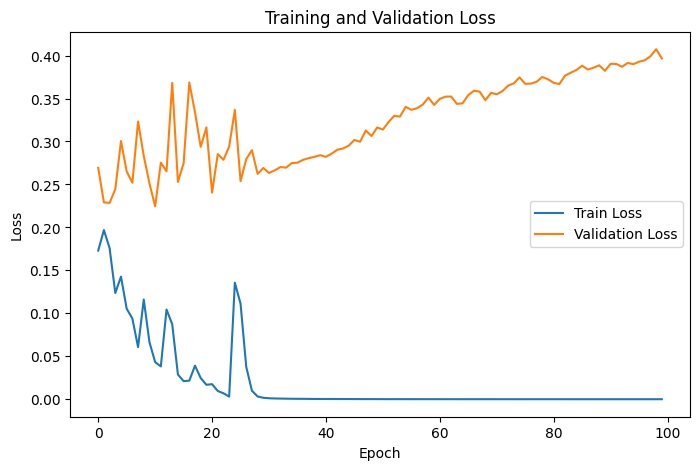

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

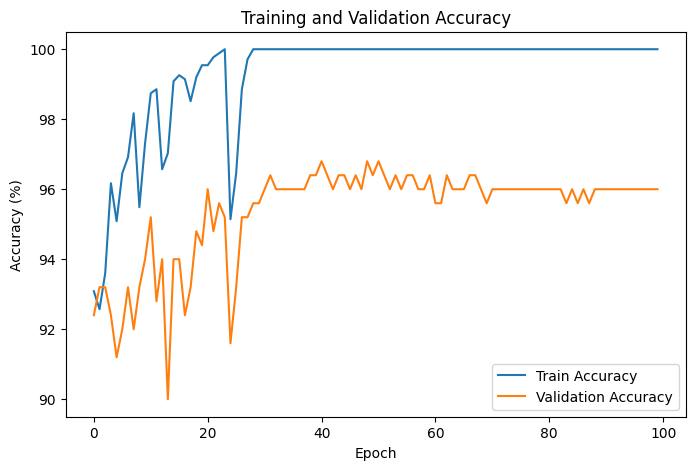

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

In [41]:
best_val_acc = max(val_accuracies)
best_acc_epoch = val_accuracies.index(best_val_acc) + 1

best_val_loss = min(val_losses)
best_loss_epoch = val_losses.index(best_val_loss) + 1

print("Best Validation Accuracy:", best_val_acc)
print("Best Accuracy Epoch:", best_acc_epoch)

print("Best Validation Loss:", best_val_loss)
print("Best Loss Epoch:", best_loss_epoch)

Best Validation Accuracy: 96.8
Best Accuracy Epoch: 41
Best Validation Loss: 0.2244961205869913
Best Loss Epoch: 11


In [42]:
test_loss, test_accuracy = validate(
    model,
    test_loader,
    criterion,
    device
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.35760589358687866
Test Accuracy: 95.0


In [43]:
class PapayaCNN4Block(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=40,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(
                in_channels=40,
                out_channels=70,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(
                in_channels=70,
                out_channels=100,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 4 - NEW
            nn.Conv2d(
                in_channels=100,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Fixed output size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, 5)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [44]:
model4 = PapayaCNN4Block().to(device)

print(model4)

PapayaCNN4Block(
  (features): Sequential(
    (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(40, 70, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(70, 100, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(100, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=5, bia

In [45]:
total_params_4 = sum(
    p.numel()
    for p in model4.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params_4)

Trainable parameters: 730647


In [46]:
criterion4 = nn.CrossEntropyLoss()

optimizer4 = torch.optim.Adam(
    model4.parameters(),
    lr=0.001
)

epochs = 100

In [47]:
train_losses4 = []
train_accuracies4 = []

val_losses4 = []
val_accuracies4 = []

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(
        model4,
        train_loader,
        criterion4,
        optimizer4,
        device
    )

    val_loss, val_accuracy = validate(
        model4,
        val_loader,
        criterion4,
        device
    )

    train_losses4.append(train_loss)
    train_accuracies4.append(train_accuracy)

    val_losses4.append(val_loss)
    val_accuracies4.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/100] Train Loss: 1.3161 | Train Acc: 43.71% | Val Loss: 0.9184 | Val Acc: 64.80%
Epoch [2/100] Train Loss: 0.8167 | Train Acc: 67.71% | Val Loss: 0.6339 | Val Acc: 73.60%
Epoch [3/100] Train Loss: 0.6295 | Train Acc: 76.86% | Val Loss: 0.7246 | Val Acc: 72.40%
Epoch [4/100] Train Loss: 0.5592 | Train Acc: 78.17% | Val Loss: 0.5906 | Val Acc: 77.20%
Epoch [5/100] Train Loss: 0.4790 | Train Acc: 82.17% | Val Loss: 0.5386 | Val Acc: 78.00%
Epoch [6/100] Train Loss: 0.4105 | Train Acc: 84.74% | Val Loss: 0.3711 | Val Acc: 87.20%
Epoch [7/100] Train Loss: 0.3382 | Train Acc: 87.60% | Val Loss: 0.3248 | Val Acc: 88.80%
Epoch [8/100] Train Loss: 0.2908 | Train Acc: 90.06% | Val Loss: 0.3201 | Val Acc: 88.80%
Epoch [9/100] Train Loss: 0.2193 | Train Acc: 93.09% | Val Loss: 0.3219 | Val Acc: 87.20%
Epoch [10/100] Train Loss: 0.2061 | Train Acc: 92.46% | Val Loss: 0.2595 | Val Acc: 92.40%
Epoch [11/100] Train Loss: 0.2081 | Train Acc: 92.40% | Val Loss: 0.2410 | Val Acc: 94.40%
Epoch [1

In [48]:
test_loss4, test_accuracy4 = validate(
    model4,
    test_loader,
    criterion4,
    device
)

print("4-Block Test Loss:", test_loss4)
print("4-Block Test Accuracy:", test_accuracy4)

4-Block Test Loss: 0.48142594406022
4-Block Test Accuracy: 94.6


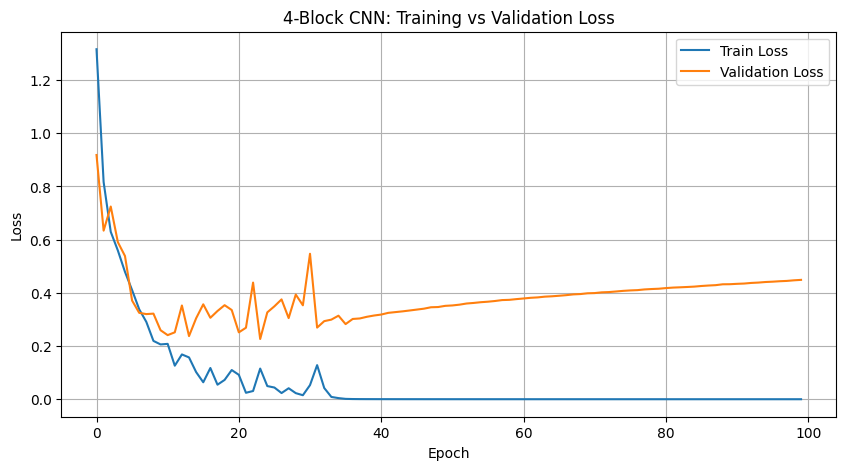

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses4, label="Train Loss")
plt.plot(val_losses4, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("4-Block CNN: Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

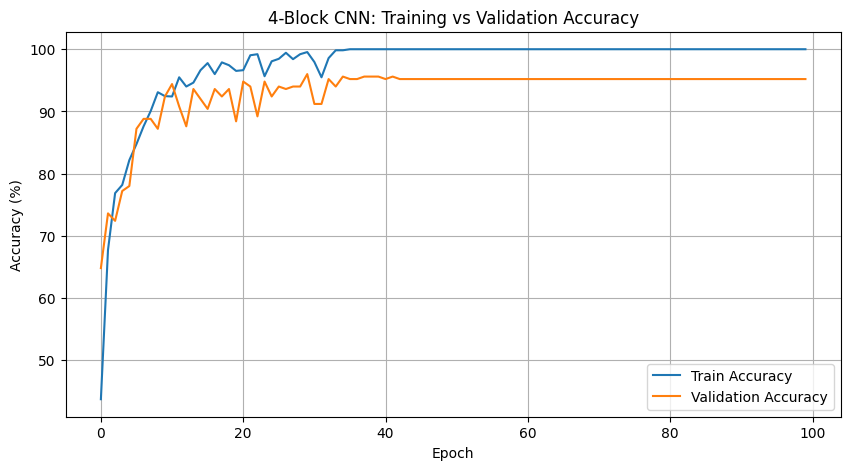

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(train_accuracies4, label="Train Accuracy")
plt.plot(val_accuracies4, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("4-Block CNN: Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [53]:
import torch.nn as nn

class PapayaCNN4Block3Hidden(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # CNN Block 1
            nn.Conv2d(
                in_channels=3,
                out_channels=40,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # CNN Block 2
            nn.Conv2d(
                in_channels=40,
                out_channels=70,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # CNN Block 3
            nn.Conv2d(
                in_channels=70,
                out_channels=100,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # CNN Block 4
            nn.Conv2d(
                in_channels=100,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Make feature map fixed at 4 × 4
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(

            # Hidden Layer 1
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),

            # Hidden Layer 2
            nn.Linear(256, 128),
            nn.ReLU(),

            # Hidden Layer 3
            nn.Linear(128, 64),
            nn.ReLU(),

            # Output Layer
            nn.Linear(64, 5)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x

In [54]:
model5 = PapayaCNN4Block3Hidden().to(device)

print(model5)

PapayaCNN4Block3Hidden(
  (features): Sequential(
    (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(40, 70, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(70, 100, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(100, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features

In [55]:
total_params_5 = sum(
    p.numel()
    for p in model5.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params_5)

Trainable parameters: 770839


In [56]:
criterion5 = nn.CrossEntropyLoss()

optimizer5 = torch.optim.Adam(
    model5.parameters(),
    lr=0.001
)

epochs = 100

In [57]:
train_losses5 = []
train_accuracies5 = []

val_losses5 = []
val_accuracies5 = []

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model5,
        train_loader,
        criterion5,
        optimizer5,
        device
    )

    val_loss, val_acc = validate(
        model5,
        val_loader,
        criterion5,
        device
    )

    train_losses5.append(train_loss)
    train_accuracies5.append(train_acc)

    val_losses5.append(val_loss)
    val_accuracies5.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/100] Train Loss: 1.3531 | Train Acc: 40.34% | Val Loss: 1.0761 | Val Acc: 58.00%
Epoch [2/100] Train Loss: 1.0246 | Train Acc: 57.26% | Val Loss: 0.8705 | Val Acc: 72.00%
Epoch [3/100] Train Loss: 0.8350 | Train Acc: 66.51% | Val Loss: 0.7101 | Val Acc: 76.80%
Epoch [4/100] Train Loss: 0.7519 | Train Acc: 70.80% | Val Loss: 0.6681 | Val Acc: 74.00%
Epoch [5/100] Train Loss: 0.6522 | Train Acc: 73.71% | Val Loss: 0.6376 | Val Acc: 76.40%
Epoch [6/100] Train Loss: 0.6150 | Train Acc: 74.00% | Val Loss: 0.5608 | Val Acc: 76.80%
Epoch [7/100] Train Loss: 0.5459 | Train Acc: 77.83% | Val Loss: 0.5517 | Val Acc: 81.60%
Epoch [8/100] Train Loss: 0.5402 | Train Acc: 78.63% | Val Loss: 0.6579 | Val Acc: 79.20%
Epoch [9/100] Train Loss: 0.4727 | Train Acc: 80.00% | Val Loss: 0.4565 | Val Acc: 82.80%
Epoch [10/100] Train Loss: 0.4033 | Train Acc: 83.94% | Val Loss: 0.4659 | Val Acc: 84.80%
Epoch [11/100] Train Loss: 0.3847 | Train Acc: 84.74% | Val Loss: 0.3961 | Val Acc: 86.00%
Epoch [1

In [58]:
best_val_acc5 = max(val_accuracies5)
best_val_acc5_epoch = val_accuracies5.index(best_val_acc5) + 1

best_val_loss5 = min(val_losses5)
best_val_loss5_epoch = val_losses5.index(best_val_loss5) + 1

print("Best Validation Accuracy:", best_val_acc5)
print("Best Validation Accuracy Epoch:", best_val_acc5_epoch)

print("Best Validation Loss:", best_val_loss5)
print("Best Validation Loss Epoch:", best_val_loss5_epoch)

Best Validation Accuracy: 95.2
Best Validation Accuracy Epoch: 63
Best Validation Loss: 0.23848732840269804
Best Validation Loss Epoch: 45


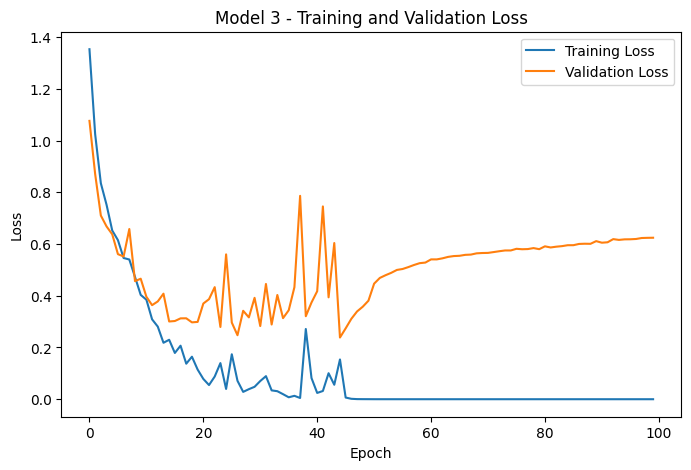

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses5, label="Training Loss")
plt.plot(val_losses5, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 3 - Training and Validation Loss")

plt.legend()
plt.show()

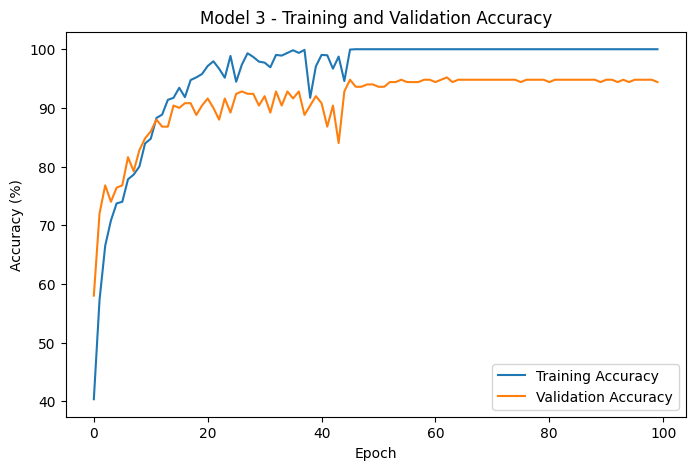

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies5, label="Training Accuracy")
plt.plot(val_accuracies5, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Model 3 - Training and Validation Accuracy")

plt.legend()
plt.show()

In [61]:
import torch.nn as nn

class PapayaCNN5Block5Hidden(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # CNN Block 1
            nn.Conv2d(3, 40, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # CNN Block 2
            nn.Conv2d(40, 70, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # CNN Block 3
            nn.Conv2d(70, 100, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # CNN Block 4
            nn.Conv2d(100, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # CNN Block 5
            nn.Conv2d(128, 160, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Fixed feature map
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(

            # Hidden Layer 1
            nn.Flatten(),
            nn.Linear(160 * 4 * 4, 256),
            nn.ReLU(),

            # Hidden Layer 2
            nn.Linear(256, 128),
            nn.ReLU(),

            # Hidden Layer 3
            nn.Linear(128, 64),
            nn.ReLU(),

            # Hidden Layer 4
            nn.Linear(64, 32),
            nn.ReLU(),

            # Hidden Layer 5
            nn.Linear(32, 16),
            nn.ReLU(),

            # Output Layer
            nn.Linear(16, 5)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [62]:
model6 = PapayaCNN5Block5Hidden().to(device)

print(model6)

PapayaCNN5Block5Hidden(
  (features): Sequential(
    (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(40, 70, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(70, 100, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(100, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 160, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier)

In [63]:
total_params_6 = sum(
    p.numel()
    for p in model6.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params_6)

Trainable parameters: 1088759


In [64]:
criterion6 = nn.CrossEntropyLoss()

optimizer6 = torch.optim.Adam(
    model6.parameters(),
    lr=0.001
)

epochs = 50

In [65]:
train_losses6 = []
train_accuracies6 = []

val_losses6 = []
val_accuracies6 = []

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model6,
        train_loader,
        criterion6,
        optimizer6,
        device
    )

    val_loss, val_acc = validate(
        model6,
        val_loader,
        criterion6,
        device
    )

    train_losses6.append(train_loss)
    train_accuracies6.append(train_acc)

    val_losses6.append(val_loss)
    val_accuracies6.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/50] Train Loss: 1.6097 | Train Acc: 19.09% | Val Loss: 1.5621 | Val Acc: 23.60%
Epoch [2/50] Train Loss: 1.3847 | Train Acc: 36.80% | Val Loss: 1.1816 | Val Acc: 50.80%
Epoch [3/50] Train Loss: 1.0720 | Train Acc: 52.46% | Val Loss: 1.0244 | Val Acc: 52.00%
Epoch [4/50] Train Loss: 0.9842 | Train Acc: 55.77% | Val Loss: 0.9254 | Val Acc: 58.00%
Epoch [5/50] Train Loss: 0.9304 | Train Acc: 58.40% | Val Loss: 0.8705 | Val Acc: 61.20%
Epoch [6/50] Train Loss: 0.8207 | Train Acc: 65.26% | Val Loss: 0.8393 | Val Acc: 67.20%
Epoch [7/50] Train Loss: 0.6969 | Train Acc: 72.91% | Val Loss: 0.6934 | Val Acc: 71.60%
Epoch [8/50] Train Loss: 0.6447 | Train Acc: 74.11% | Val Loss: 0.6558 | Val Acc: 73.20%
Epoch [9/50] Train Loss: 0.5902 | Train Acc: 77.49% | Val Loss: 0.4884 | Val Acc: 82.00%
Epoch [10/50] Train Loss: 0.4854 | Train Acc: 82.11% | Val Loss: 0.4210 | Val Acc: 82.80%
Epoch [11/50] Train Loss: 0.4621 | Train Acc: 81.43% | Val Loss: 0.3975 | Val Acc: 84.80%
Epoch [12/50] Train

In [5]:
best_val_acc6 = max(val_accuracies6)
best_val_acc6_epoch = val_accuracies6.index(best_val_acc6) + 1

best_val_loss6 = min(val_losses6)
best_val_loss6_epoch = val_losses6.index(best_val_loss6) + 1

print("Best Validation Accuracy:", best_val_acc6)
print("Best Validation Accuracy Epoch:", best_val_acc6_epoch)

print("Best Validation Loss:", best_val_loss6)
print("Best Validation Loss Epoch:", best_val_loss6_epoch)

NameError: name 'val_accuracies6' is not defined

In [6]:
print("train_losses6" in globals())
print("train_accuracies6" in globals())
print("val_losses6" in globals())
print("val_accuracies6" in globals())

False
False
False
False


In [7]:
val_accuracies6 = [
    23.60, 50.80, 52.00, 58.00, 61.20,
    67.20, 71.60, 73.20, 82.00, 82.80,
    84.80, 86.80, 88.40, 86.40, 86.80,
    90.80, 86.40, 88.00, 90.00, 88.00,
    91.60, 89.20, 85.60, 88.80, 92.40,
    90.80, 91.60, 92.40, 90.80, 91.60,
    94.00, 94.40, 92.80, 90.80, 92.80,
    93.60, 94.00, 89.60, 90.40, 91.60,
    91.20, 91.20, 90.40, 92.80, 92.80,
    90.80, 92.80, 93.20, 93.60, 92.00
]

val_losses6 = [
    1.5621, 1.1816, 1.0244, 0.9254, 0.8705,
    0.8393, 0.6934, 0.6558, 0.4884, 0.4210,
    0.3975, 0.4128, 0.3164, 0.3386, 0.3611,
    0.2232, 0.2793, 0.4247, 0.2685, 0.2624,
    0.3293, 0.3486, 0.4581, 0.3495, 0.3176,
    0.3254, 0.3049, 0.2435, 0.4004, 0.2485,
    0.2476, 0.2091, 0.2399, 0.3669, 0.4258,
    0.3325, 0.2150, 0.3696, 0.4219, 0.3207,
    0.3402, 0.4927, 0.3116, 0.2883, 0.4449,
    0.4585, 0.4168, 0.3504, 0.2917, 0.3522
]

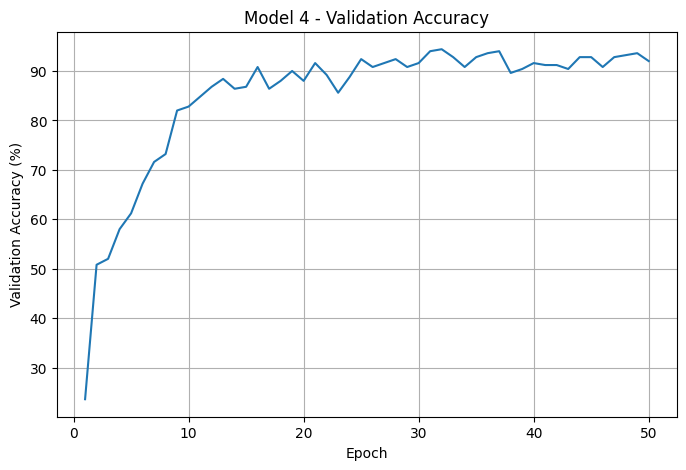

In [8]:
import matplotlib.pyplot as plt

epochs = range(1, len(val_accuracies6) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, val_accuracies6)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Model 4 - Validation Accuracy")

plt.grid(True)
plt.show()

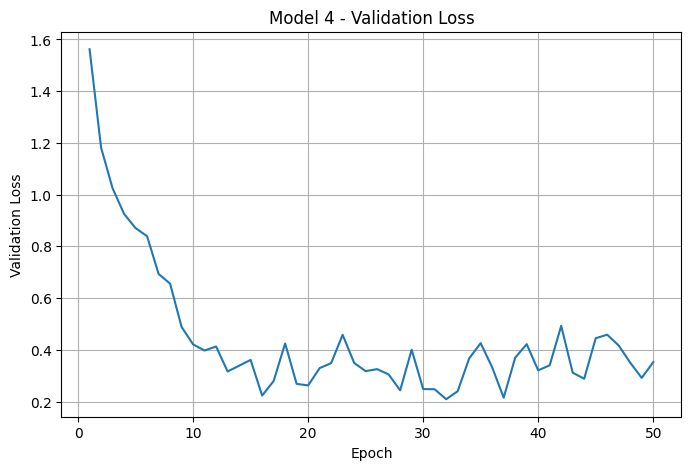

In [9]:
epochs = range(1, len(val_losses6) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, val_losses6)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Model 4 - Validation Loss")

plt.grid(True)
plt.show()

In [10]:
train_accuracies6 = [
    19.09, 36.80, 52.46, 55.77, 58.40,
    65.26, 72.91, 74.11, 77.49, 82.11,
    81.43, 84.11, 85.71, 88.57, 88.17,
    90.63, 92.00, 91.26, 92.06, 92.80,
    93.03, 92.86, 89.71, 91.14, 95.26,
    95.60, 97.37, 97.14, 96.86, 95.09,
    96.97, 96.63, 96.91, 98.57, 98.34,
    99.26, 98.51, 88.00, 97.77, 97.49,
    98.00, 99.49, 98.23, 98.46, 99.26,
    98.11, 99.31, 98.29, 97.77, 99.09
]

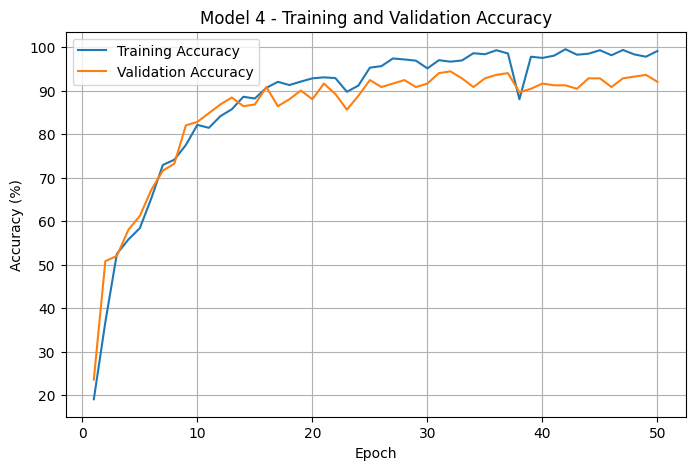

In [11]:
epochs = range(1, len(train_accuracies6) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_accuracies6,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracies6,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Model 4 - Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [12]:
train_losses6 = [
    1.6097, 1.3847, 1.0720, 0.9842, 0.9304,
    0.8207, 0.6969, 0.6447, 0.5902, 0.4854,
    0.4621, 0.4135, 0.3838, 0.3084, 0.3258,
    0.2432, 0.2301, 0.2448, 0.2112, 0.1774,
    0.1889, 0.2042, 0.2854, 0.2491, 0.1327,
    0.1033, 0.0782, 0.0794, 0.0927, 0.1408,
    0.0840, 0.1021, 0.0935, 0.0495, 0.0568,
    0.0221, 0.0507, 0.3481, 0.0636, 0.0701,
    0.0499, 0.0206, 0.0470, 0.0577, 0.0219,
    0.0531, 0.0210, 0.0472, 0.0628, 0.0281
]

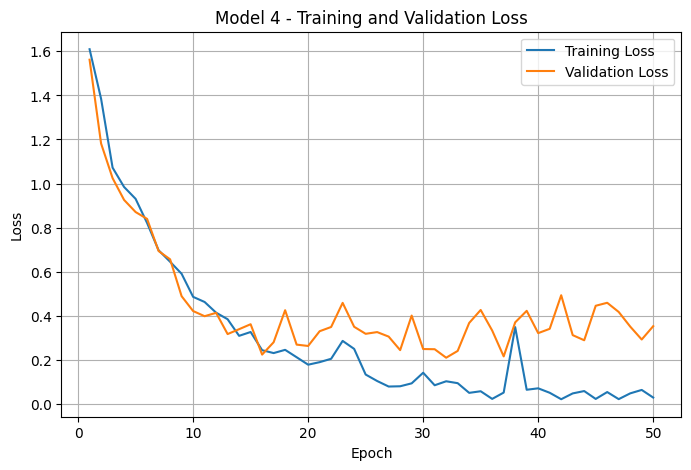

In [13]:
epochs = range(1, len(train_losses6) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses6,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses6,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 4 - Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
import pandas as pd

In [16]:
model_comparison = {
    "Model": [
        "Model 1",
        "Model 2",
        "Model 3",
        "Model 4"
    ],
    "CNN Blocks": [
        3,
        4,
        4,
        5
    ],
    "Hidden Layers": [
        1,
        1,
        3,
        5
    ],
    "Best Validation Accuracy (%)": [
        96.8,
        96.0,
        95.2,
        94.4
    ]
}

comparison_df = pd.DataFrame(model_comparison)

comparison_df

,Model,CNN Blocks,Hidden Layers,Best Validation Accuracy (%)
0,Model 1,3,1,96.8
1,Model 2,4,1,96.0
2,Model 3,4,3,95.2
3,Model 4,5,5,94.4


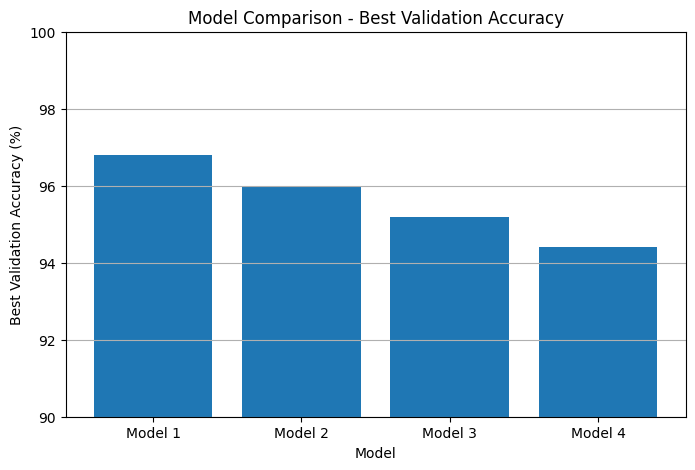

In [17]:
models = comparison_df["Model"]
accuracies = comparison_df["Best Validation Accuracy (%)"]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.xlabel("Model")
plt.ylabel("Best Validation Accuracy (%)")
plt.title("Model Comparison - Best Validation Accuracy")

plt.ylim(90, 100)
plt.grid(axis="y")

plt.show()

In [18]:
print("model" in globals())
print("test_loader" in globals())

False
False


In [19]:
print("Best Validation Accuracy: 96.8%")
print("Best Validation Accuracy Epoch: 41")

print("Test Loss: 0.3576")
print("Test Accuracy: 95.0%")

Best Validation Accuracy: 96.8%
Best Validation Accuracy Epoch: 41
Test Loss: 0.3576
Test Accuracy: 95.0%


In [21]:
import torch
import torch.nn as nn

In [22]:
class PapayaCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 40, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(40, 70, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(70, 100, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(100 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, 5)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [23]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [25]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith(('.pth', '.pt', '.ckpt')):
            print(os.path.join(root, file))